In [190]:
%matplotlib inline 

In [191]:
import os
import io
import re
import itertools
import numpy as np
import pandas as pd
import json

In [227]:
data_sources = ['mnd_TSC']

distr_dims = ['-'.join(['Distancegroup', 'Legs', 'Timeperiodseq']),
              '-'.join(['Distancegroup', 'Legs'])]

aggr_levels = ['lsoa', 'msoa']
perc_sample_sizes = ['sample_perc_10']
export = False
out_folder = r'./outputs'
tolerance = 0.01

run_info = list(itertools.product(data_sources, distr_dims, aggr_levels, perc_sample_sizes))

In [228]:
def prepare_results_filepaths(run_results_fldr):
    flpaths = dict()
    flpaths['od'] = os.path.join(run_results_fldr, 'od_filtered.csv')
    flpaths['trs_obs_descr'] = os.path.join(run_results_fldr, 'trs_obs_descr.csv')
    flpaths['trs_obs_info'] = os.path.join(run_results_fldr, 'trs_obs_info.csv')
    flpaths['trs_mdl_descr'] = os.path.join(run_results_fldr, 'trs_mdl_descr.csv')
    flpaths['trs_mdl_info'] = os.path.join(run_results_fldr, 'trs_mdl_info.csv')
    flpaths['observed_distribution'] = os.path.join(run_results_fldr, 'target_distribution.csv')
    flpaths['optimisation_results'] = os.path.join(run_results_fldr, 'results.json')
    flpaths['trs_descr_comp'] = os.path.join(run_results_fldr, 'trs_descr_comp.csv')
    flpaths['metadata'] = os.path.join(run_results_fldr, 'metadata.json')
    return flpaths

In [229]:
def read_metadata(filepath):
    return pd.read_json(filepath, typ='series')

In [230]:
def read_zones_info(filepath, index_col='Zoneid'):
    return pd.read_csv(filepath, index_col=index_col)

In [231]:
def prepare_od_from_tours(trs_info, trs_descr, od_dims, name='Trips'):
    times_used = trs_info['Timesused']
    trs_descr = trs_descr.join(times_used)
    od = trs_descr.groupby(od_dims)['Timesused'].sum()
    od.name = name
    return od

In [232]:
def prepare_od_comparison(od_mdl, od_obs):
    od_obs.name = 'ObservedTrips'
    comp = od_obs.to_frame().join(od_mdl)
    comp.columns.name = 'TripsSource'
    comp = comp.stack()
    comp.name = 'Trips'
    return comp

In [233]:
def get_input_params_from_folder(infldr):
    fldrs = [name for name in os.listdir(infldr) if os.path.isdir(os.path.join(infldr, name))]
    inputs = []
    for fldr in fldrs:
        matches = re.findall('(\d+)legs-over(\d+)trips-distrConstr(\w+)', fldr)
        if matches:
            legs = int(matches[0][0])
            trips = int(matches[0][1])
            if matches[0][2] == 'True':
                distr_constr_enabled = True
            elif matches[0][2] == 'False':
                distr_constr_enabled = False
            else:
                raise ValueError('distrConstrEnabled must be either True or False')
                
            inputs.append([legs, trips, distr_constr_enabled])
        
    return inputs

In [234]:
def prepare_distribution_comparison(trs_mdl_info, obs_distr):
    
    obs_distr.drop(columns=['Size'], inplace=True)

    optim_distr = trs_mdl_info.groupby('Distrgroupid')['Timesused'].sum()
    optim_distr = optim_distr.div(optim_distr.sum())
    optim_distr.name = 'Percentage'
    
    # We need to identify the distribution dimensions cols (should be all apart form the Percentage)
    idx_cols = list()
    for c in obs_distr.columns:
        if c != 'Percentage':
            idx_cols.append(c)
    
    obs_distr.set_index(idx_cols, append=True).squeeze()
    
    distr_comp = obs_distr['Percentage'].to_frame().join(optim_distr, rsuffix='_')
    distr_comp.columns = ['obs', 'mdl']
    distr_comp.columns.name = 'Type'
    distr_comp = distr_comp.stack('Type')
    distr_comp.name = 'Percentage'

    return distr_comp

In [235]:
def collapse_tour_legs(trs, leg_descr_cols, idx_cols=['Tourid']):
    seqs = list()
    for c in leg_descr_cols:
        seq = trs.groupby(level=idx_cols)[c].apply(tuple)
        seqs.append(seq)
    
    trs_collapsed = pd.concat(seqs, axis=1)
    
    return trs_collapsed

In [236]:
def include_run_info(df, d_run_params):
    try:
        df = df.to_frame()
    except AttributeError:
        pass
    
    for k, v in d_run_params.items():
        df[k] = v
        
    df.set_index(list(d_run_params.keys()), append=True, inplace=True)
    df = df.squeeze()
    return df

In [237]:
def compare_times_used(comp_descr, trs_obs_info, trs_mdl_info,
                       leg_descr_cols, idx_cols):
    
    trs_obs_info['Type'] = 'obs'
    trs_mdl_info['Type'] = 'mdl'
    
    trs_obs_info.set_index('Type', append=True, inplace=True)
    trs_mdl_info.set_index('Type', append=True, inplace=True)
    trs_obs_info = trs_obs_info.swaplevel()
    trs_mdl_info = trs_mdl_info.swaplevel()
    
    times_used = pd.concat([trs_obs_info['Timesused'], 
                            trs_mdl_info['Timesused']])
    
    #df = collapse_tour_legs(comp_descr, leg_descr_cols, idx_cols)
    df = comp_descr.join(times_used)
    
    obs = df.xs('obs', level='Type', drop_level=False)
    mdl = df.xs('mdl', level='Type', drop_level=False)
    
    obs = obs.groupby(leg_descr_cols)['Timesused'].sum()
    mdl = mdl.groupby(leg_descr_cols)['Timesused'].sum()
    
    mrg = pd.merge(obs.to_frame(), mdl.to_frame(),
                   left_index=True, right_index=True,
                   how='outer',
                   suffixes=('_obs', '_mdl')).fillna(0)

    mrg.columns.name = 'Type'
    mrg.rename(columns=lambda x: x.replace('Timesused_', ''), inplace=True)
    mrg = mrg.stack()
    mrg.name = 'Timesused'

    df = mrg.unstack()
    df['Diff'] = df['obs'] - df['mdl']
    df['Diffabs'] = df['Diff'].abs()
    comp_times_used = df
    
    return comp_times_used

In [238]:
def prepare_run_info_dict(run_params):
    (data_source, distr_dims, aggr_level, sample_size,
     legs, trips_thresh, distr_constr_enabled) = run_params
    
    d_run_params = dict()
    d_run_params['DataSource'] = data_source
    d_run_params['AggrLevel'] = aggr_level
    d_run_params['SampleSize'] = sample_size
    d_run_params['DistrDims'] = distr_dims
    d_run_params['MaxLegs'] = int(legs)
    d_run_params['TripsThresh'] = int(trips_thresh)
    d_run_params['DistrConstr'] = distr_constr_enabled
    return d_run_params

In [239]:
def main(model_info):
    
    data_source, distr_dims, aggr_level, sample_size = model_info
    
    results_folder = r'../outputs/{}/{}/{}/{}'.format(data_source, distr_dims, aggr_level, sample_size)
    params = get_input_params_from_folder(results_folder)

    concat_od_mdl = list()
    concat_od_obs = list()

    concat_trs_mdl_used_descr = list()

    concat_comp_distrs = list()
    concat_comp_descrs = list()
    concat_comp_times_used = list()
    concat_metadata = list()
    
    for legs, trips_thresh, distr_constr_enabled in params:

        print(data_source, distr_dims, aggr_level, legs, trips_thresh, distr_constr_enabled)
        run_info = model_info.copy()
        
        run_tmplt = '{}legs-over{}trips-distrConstr{}'.format(legs, trips_thresh, distr_constr_enabled)
        run_results_fldr = os.path.join(results_folder, run_tmplt)

        flpaths = prepare_results_filepaths(run_results_fldr)
        
        metadata = read_metadata(flpaths['metadata'])
        
        obs_distr = pd.read_csv(flpaths['observed_distribution'], index_col='Distrgroupid')

        trs_obs_info = pd.read_csv(flpaths['trs_obs_info'], index_col=['Tourid'])
        trs_obs_descr = pd.read_csv(flpaths['trs_obs_descr'], index_col=['Tourid', 'Legidx'])
    
        trs_mdl_info = pd.read_csv(flpaths['trs_mdl_info'], index_col=['Tourid'])
        trs_mdl_descr = pd.read_csv(flpaths['trs_mdl_descr'], index_col=['Tourid', 'Legidx'])
    
        od_dims = ['Source', 'Target', 'Purpose', 'Direction', 'Timeperiod']
        
        # For the observed tours prepare the od only for the high frequency tours
        # trs_obs_info['Timesused'] = np.where(trs_obs_info['Inlowfreqgroup'], 0, 1)
        
        od_obs = prepare_od_from_tours(trs_obs_info, trs_obs_descr,
                                       od_dims=od_dims, name='ObservedTrips')
        
        od_mdl = prepare_od_from_tours(trs_mdl_info, trs_mdl_descr,
                                       od_dims=od_dims, name='ModelledTrips')
        
        if od_mdl is None:
            print('No results for legs:{}-trips:{}-distrConstr:{}'.format(legs, trips_thresh, distr_constr_enabled))
            continue

        comp_distr = prepare_distribution_comparison(trs_mdl_info, obs_distr)

        usecols = ['Type', 'Tourid', 'Legidx',
                   'Source', 'Target', 'Purpose', 'Direction', 'Timeperiod',
                   'Inboth', 'Inlowfreqgroup']
        
        comp_descr = pd.read_csv(flpaths['trs_descr_comp'],
                                 usecols=usecols,
                                 index_col=['Type', 'Tourid', 'Legidx'])
        
        leg_descr_cols = ['Source', 'Target', 'Timeperiod']
        idx_cols = ['Type', 'Tourid']
        comp_times_used = compare_times_used(comp_descr,
                                             trs_obs_info, trs_mdl_info,
                                             leg_descr_cols, idx_cols)
        
        run_info.extend([legs, trips_thresh, distr_constr_enabled])
        d_run_info = prepare_run_info_dict(run_info)
        
        od_obs = include_run_info(od_obs, d_run_info)
        od_mdl = include_run_info(od_mdl, d_run_info)
        comp_distr = include_run_info(comp_distr, d_run_info)
        comp_descr = include_run_info(comp_descr, d_run_info)
        comp_times_used = include_run_info(comp_times_used, d_run_info)
        
        concat_metadata.append(metadata)
        concat_od_mdl.append(od_mdl)
        concat_od_obs.append(od_obs)
        concat_comp_descrs.append(comp_descr)
        concat_comp_distrs.append(comp_distr)
        concat_comp_times_used.append(comp_times_used)

    metadata = pd.concat(concat_metadata, axis=1)
    od_mdl = pd.concat(concat_od_mdl)
    od_obs = pd.concat(concat_od_obs)

    comp_ods = prepare_od_comparison(od_mdl, od_obs)
    comp_distrs = pd.concat(concat_comp_distrs)
    comp_descrs = pd.concat(concat_comp_descrs)
    comp_times_used = pd.concat(concat_comp_times_used)
    
    return metadata, comp_ods, comp_distrs, comp_descrs, comp_times_used

In [240]:
comparisons = dict()

ods = list()
distrs = list()
descrs = list()
times_used = list()
metadata = list()

for ri in run_info:
    mdata, comp_ods, comp_distrs, comp_descrs, comp_times_used = main(list(ri))    
    metadata.append(mdata)
    ods.append(comp_ods)
    distrs.append(comp_distrs)
    descrs.append(comp_descrs)
    times_used.append(comp_times_used)

infolder = r'../inputs/mnd_TSC'
zones_info = read_zones_info(os.path.join(infolder, 'zones_info.csv'))
    
comparisons['metadata'] = pd.concat(metadata, axis=1)
comparisons['metadata'].columns = list(range(1, comparisons['metadata'].shape[1] + 1))
comparisons['metadata'].columns.name = 'RunId'
comparisons['ods'] = pd.concat(ods)
comparisons['distrs'] = pd.concat(distrs)
comparisons['descrs'] = pd.concat(descrs)
comparisons['timesused'] = pd.concat(times_used)

if export:
    print('Exporting...')
    #mdl_nchains.to_csv(os.path.join(out_folder, 'optimisation_results.csv'), header=True, index=True)
    comparisons['metadata'].to_csv(os.path.join(out_folder, 'metadata.csv'), header=True)
    comparisons['ods'].to_csv(os.path.join(out_folder, 'comparison_od.csv'), header=True)
    comparisons['distrs'].to_csv(os.path.join(out_folder, 'comparison_distributions.csv'), header=True, index=True)
    comparisons['descrs'].to_csv(os.path.join(out_folder, 'comparison_descrs.csv'), header=True, index=True)
    comparisons['timesused'].to_csv(os.path.join(out_folder, 'comparison_times_used.csv'), header=True, index=True)

mnd_TSC Distancegroup-Legs-Timeperiodseq lsoa 5 1 False
mnd_TSC Distancegroup-Legs-Timeperiodseq lsoa 5 1 True
mnd_TSC Distancegroup-Legs-Timeperiodseq msoa 5 1 False
mnd_TSC Distancegroup-Legs-Timeperiodseq msoa 5 1 True
mnd_TSC Distancegroup-Legs lsoa 5 1 False
mnd_TSC Distancegroup-Legs lsoa 5 1 True
mnd_TSC Distancegroup-Legs msoa 5 1 False
mnd_TSC Distancegroup-Legs msoa 5 1 True


In [241]:
df = comparisons['distrs'].copy()
df = df.xs(True, level='DistrConstr')
df = df.unstack('Type')
df['Diff_perc'] = df['obs'].sub(df['mdl'])

df['BelowTolerance'] = df.Diff_perc.abs() <= tolerance
df.dropna(inplace=True)
df['BelowTolerance'].all()

True

In [242]:
grpby_lvls = ['DataSource', 'DistrDims', 'AggrLevel', 'SampleSize',
              'MaxLegs', 'TripsThresh', 'DistrConstr',
              'TripsSource', 'Purpose']

df = comparisons['ods'].groupby(level=grpby_lvls).sum()

df = df.unstack('TripsSource')

df['Diff'] = df.ObservedTrips - df.ModelledTrips
df['Diff_perc'] = df.ModelledTrips/df.ObservedTrips - 1

df.style.format({
    'ModelledTrips': '{:,.0f}'.format,
    'ObservedTrips': '{:,.0f}'.format,
    'Diff': '{:,.0f}'.format,
    'Diff_perc': '{:.0%}'.format
})

In [243]:
filters = dict()
filters['DataSource'] = 'mnd_TSC'
filters['DistrDims'] = 'Distancegroup-Legs-Timeperiodseq'
filters['AggrLevel'] = 'lsoa'
filters['SampleSize'] = 'sample_perc_10'
filters['MaxLegs'] = 5
filters['TripsThresh'] = 1
#filters['DistrConstr'] = True

In [244]:
if filters:
    comparisons_filt = dict()
    for k, f in comparisons.items():
        if k!='metadata':
            comparisons_filt[k] = comparisons[k].xs(list(filters.values()),
                                                level=list(filters.keys()))
    analysis_comp = comparisons_filt.copy()
else:
    analysis_comp = comparisons.copy()

False
True


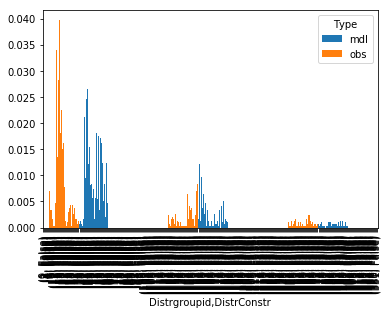

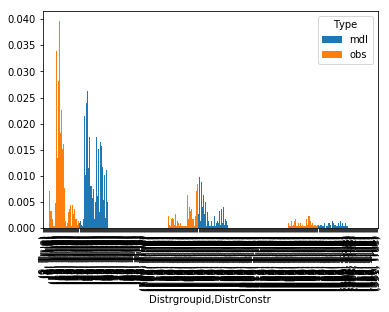

In [245]:
grpby_lvls = ['DataSource', 'AggrLevel', 'SampleSize',
              'MaxLegs', 'TripsThresh', 'DistrConstr']

grpby_lvls = [gl for gl in grpby_lvls if gl not in list(filters.keys())]

# can just unstack and plot(subplots=True)
if grpby_lvls:
    dfg = analysis_comp['distrs'].groupby(level=grpby_lvls)
    for k, g in dfg:
        print(k)
        plt = g.unstack('Type')
        plt.plot(kind='bar')

In [246]:
grpby_lvls = ['MaxLegs', 'TripsThresh', 'DistrConstr', 'Inboth']
grpby_lvls = [gl for gl in grpby_lvls if gl not in list(filters.keys())]
analysis_comp['descrs'].groupby(grpby_lvls).size().unstack('DistrConstr')

DistrConstr,False,True
Inboth,,
False,156992,156992
True,16032,16032


In [247]:
grpby_cols = ['DataSource', 'AggrLevel', 'SampleSize',
              'DistrDims', 'MaxLegs', 'TripsThresh']#, 'DistrConstr']

comparisons['timesused'].xs(True, level='DistrConstr').groupby(level=grpby_cols).sum()

Type                                                                                         obs  \
DataSource AggrLevel SampleSize     DistrDims                        MaxLegs TripsThresh           
mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs               5       1            8016.0   
                                    Distancegroup-Legs-Timeperiodseq 5       1            8016.0   
           msoa      sample_perc_10 Distancegroup-Legs               5       1            7871.0   
                                    Distancegroup-Legs-Timeperiodseq 5       1            7871.0   

Type                                                                                         mdl  \
DataSource AggrLevel SampleSize     DistrDims                        MaxLegs TripsThresh           
mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs               5       1            8016.0   
                                    Distancegroup-Legs-Timeperiodseq 5       1            8016.0   
           msoa      sample_perc_10 Distancegroup-Legs               5       1            7640.0   
                                    Distancegroup-Legs-Timeperiodseq 5       1            7488.0   

Type                                                                                       Diff  \
DataSource AggrLevel SampleSize     DistrDims                        MaxLegs TripsThresh          
mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs               5       1              0.0   
                                    Distancegroup-Legs-Timeperiodseq 5       1              0.0   
           msoa      sample_perc_10 Distancegroup-Legs               5       1            231.0   
                                    Distancegroup-Legs-Timeperiodseq 5       1            383.0   

Type                                                                                      Diffabs  
DataSource AggrLevel SampleSize     DistrDims                        MaxLegs TripsThresh           
mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs               5       1                0.0  
                                    Distancegroup-Legs-Timeperiodseq 5       1                0.0  
           msoa      sample_perc_10 Distancegroup-Legs               5       1              231.0  
                                    Distancegroup-Legs-Timeperiodseq 5       1              383.0

In [248]:
# Calculate number of missing tours 
grpby_lvls = ['DataSource', 'AggrLevel', 'SampleSize',
              'DistrDims', 'MaxLegs', 'TripsThresh', 'DistrConstr']

df = comparisons['timesused'].copy()
df = df.Diff.groupby(level=grpby_lvls).value_counts()
df.name = 'Count'
df = df.reset_index(level='Diff')
df = df.product(axis=1)
df.name = 'MissingTours'
df.groupby(level=grpby_lvls).sum()

DataSource  AggrLevel  SampleSize      DistrDims                         MaxLegs  TripsThresh  DistrConstr
mnd_TSC     lsoa       sample_perc_10  Distancegroup-Legs                5        1            False            0.0
                                                                                               True             0.0
                                       Distancegroup-Legs-Timeperiodseq  5        1            False            0.0
                                                                                               True             0.0
            msoa       sample_perc_10  Distancegroup-Legs                5        1            False          199.0
                                                                                               True           231.0
                                       Distancegroup-Legs-Timeperiodseq  5        1            False          371.0
                                                                                 

In [249]:
df = comparisons['timesused'].copy()
grpby_lvls = list(df.index.names)
grpby_lvls.remove('Timeperiod')

df = df.groupby(level=grpby_lvls).sum()
df.Diff = df.obs - df.mdl
df.Diffabs = abs(df.Diff)
df = df[df.Diff!=0]
df

Type                                                                                                                       obs  \
Source    Target    DataSource AggrLevel SampleSize     DistrDims                        MaxLegs TripsThresh DistrConstr         
E02002985 E02002998 mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False         1.0   
          E02003032 mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           True          1.0   
          E02003043 mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False         6.0   
          E02003053 mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False         1.0   
E02002986 E02002991 mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           True          1.0   
          E02003034 mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs               5       1           False         2.0   
                                                                                                             True          2.0   
          E02003043 mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False         4.0   
          E02003058 mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           True          2.0   
          E02003110 mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           True          2.0   
E02002987 E02002996 mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs               5       1           False         3.0   
          E02003004 mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False         1.0   
                                                                                                             True          1.0   
          E02003027 mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           True          2.0   
          E02003050 mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           True          1.0   
          E02003096 mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False         1.0   
          E02003112 mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs               5       1           False         1.0   
          E02006887 mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs               5       1           True          2.0   
E02002988 E02002997 mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs               5       1           False         1.0   
                                                                                                             True          1.0   
                                                        Distancegroup-Legs-Timeperiodseq 5       1           False         1.0   
                                                                                                             True          1.0   
          E02003077 mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs               5       1           False         1.0   
                                                                                                             True          1.0   
E02002991 E02002985 mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           True          1.0   
          E02002987 mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           True          2.0   
          E02003006 mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False         3.0   
          E02003010 mnd_TSC    msoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False         4.0   
                                                                                                    

In [252]:
df = comparisons['descrs'].copy()
df.head()

Source  \
Type Tourid Legidx DataSource AggrLevel SampleSize     DistrDims                        MaxLegs TripsThresh DistrConstr              
mdl  42     0      mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False        E01014405   
            1      mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False        E01033353   
            2      mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False        E01014588   
            3      mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False        E01014388   
            4      mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False        E01014370   

                                                                                                                            Target  \
Type Tourid Legidx DataSource AggrLevel SampleSize     DistrDims                        MaxLegs TripsThresh DistrConstr              
mdl  42     0      mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False        E01033353   
            1      mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False        E01014588   
            2      mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False        E01014388   
            3      mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False        E01014370   
            4      mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False        E01014405   

                                                                                                                        Purpose  \
Type Tourid Legidx DataSource AggrLevel SampleSize     DistrDims                        MaxLegs TripsThresh DistrConstr           
mdl  42     0      mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False            HB   
            1      mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False           NHB   
            2      mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False           NHB   
            3      mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False           NHB   
            4      mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False            HB   

                                                                                                                            Direction  \
Type Tourid Legidx DataSource AggrLevel SampleSize     DistrDims                        MaxLegs TripsThresh DistrConstr                 
mdl  42     0      mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False            FromHome   
            1      mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False        NonHomeBased   
            2      mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False        NonHomeBased   
            3      mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False        NonHomeBased   
            4      mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False              ToHome   

                                                                                                                        Timeperiod  \
Type Tourid Legidx DataSource AggrLevel SampleSize     DistrDims                        MaxLegs TripsThresh DistrConstr              
mdl  42     0      mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1   

In [251]:
df = comparisons['timesused'].copy()
df.head()

Type                                                                                                                                 obs  \
Source    Target    Timeperiod DataSource AggrLevel SampleSize     DistrDims                        MaxLegs TripsThresh DistrConstr        
E01014370 E01014377 PM         mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False        1.0   
          E01014379 IP         mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False        1.0   
          E01014385 PM         mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False        1.0   
          E01014387 OP         mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False        1.0   
          E01014396 IP         mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False        1.0   

Type                                                                                                                                 mdl  \
Source    Target    Timeperiod DataSource AggrLevel SampleSize     DistrDims                        MaxLegs TripsThresh DistrConstr        
E01014370 E01014377 PM         mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False        1.0   
          E01014379 IP         mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False        1.0   
          E01014385 PM         mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False        1.0   
          E01014387 OP         mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False        1.0   
          E01014396 IP         mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False        1.0   

Type                                                                                                                                 Diff  \
Source    Target    Timeperiod DataSource AggrLevel SampleSize     DistrDims                        MaxLegs TripsThresh DistrConstr         
E01014370 E01014377 PM         mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False         0.0   
          E01014379 IP         mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False         0.0   
          E01014385 PM         mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False         0.0   
          E01014387 OP         mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False         0.0   
          E01014396 IP         mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False         0.0   

Type                                                                                                                                 Diffabs  
Source    Target    Timeperiod DataSource AggrLevel SampleSize     DistrDims                        MaxLegs TripsThresh DistrConstr           
E01014370 E01014377 PM         mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False            0.0  
          E01014379 IP         mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False            0.0  
          E01014385 PM         mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False            0.0  
          E01014387 OP         mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False            0.0  
          E01014396 IP         mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs-Timeperiodseq 5       1           False            0.0

In [132]:
df = comparisons['descrs'].copy()
cat_cols = ['Source', 'Target', 'Purpose', 'Direction', 'Timeperiod']
tup_cols = ['Source', 'Timeperiod'] 
df = df[tup_cols].groupby(level=list(set(df.index.names)^set(['Legidx']))).agg(tuple)
df.head()

Source  \
DataSource AggrLevel SampleSize     MaxLegs Tourid TripsThresh Type DistrConstr DistrDims                                                               
mnd_TSC    lsoa      sample_perc_10 5       27     1           mdl  False       Distancegroup-Legs  (E01014405, E01033353, E01014588, E01033339, E...   
                                                                    True        Distancegroup-Legs  (E01014405, E01033353, E01014588, E01033339, E...   
                                            28     1           mdl  False       Distancegroup-Legs  (E01014405, E01033353, E01014588, E01033339, E...   
                                                                    True        Distancegroup-Legs  (E01014405, E01033353, E01014588, E01033339, E...   
                                            32     1           mdl  False       Distancegroup-Legs  (E01014405, E01033353, E01014588, E01033339, E...   

                                                                                                              Timeperiod  
DataSource AggrLevel SampleSize     MaxLegs Tourid TripsThresh Type DistrConstr DistrDims                                 
mnd_TSC    lsoa      sample_perc_10 5       27     1           mdl  False       Distancegroup-Legs  (AM, AM, IP, IP, OP)  
                                                                    True        Distancegroup-Legs  (AM, AM, IP, IP, OP)  
                                            28     1           mdl  False       Distancegroup-Legs  (AM, IP, IP, IP, OP)  
                                                                    True        Distancegroup-Legs  (AM, IP, IP, IP, OP)  
                                            32     1           mdl  False       Distancegroup-Legs  (IP, IP, IP, IP, OP)

In [25]:
df = comparisons['ods'].copy()
df = df.xs(['ObservedTrips', True, 'Distancegroup-Legs-Timeperiodseq'],
           level=['TripsSource', 'DistrConstr', 'DistrDims'])

grpby_lvls = ['DataSource', 'AggrLevel', 'SampleSize', 'MaxLegs', 'TripsThresh']

vcnts = df.groupby(level=grpby_lvls).value_counts()
tots_gs = vcnts.groupby(level=grpby_lvls).apply(lambda x: x.div(x.sum()))


array([<matplotlib.axes._subplots.AxesSubplot object at 0x00000224BAD8DA58>,
      dtype=object)

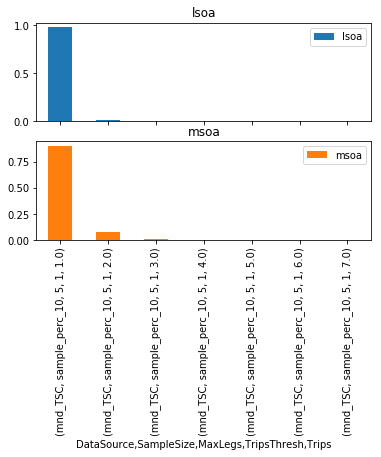

In [26]:
tots_gs.unstack('AggrLevel').plot(kind='bar', subplots=True)